<a href="https://colab.research.google.com/github/Jainwinsarthak/rf-pm-sensing/blob/main/Final_year_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np   # import lib and define no of sample to be gen
import matplotlib.pyplot as plt
n = 10000

In [ ]:
#genert wireless channel cofficent
rng = np.random.default_rng(42)
h_real = rng.normal(0, 1, n)
h_imag = rng.normal(0, 1, n)
h = h_real + 1j * h_imag
#print("Actual channel:", h)

In [ ]:
x = 1 + 1j  # Define transmited signal

In [ ]:
channel_variance=2.0

snr_db =np.arange(0,26)

mse_zfm=[]
mse_mmse=[]

In [ ]:
noise_real = rng.normal(0,1,n)  #(means,sd,value)
noise_imag = 1j*rng.normal(0, 1, n)
noise_unit =(noise_real+noise_imag)/np.sqrt(2) #cal noise unit

In [ ]:
for snr in snr_db:
  snr_linear = 10**(snr/10)
  noise_variance = 1/snr_linear
  noise= np.sqrt(noise_variance)*noise_unit


#synthesising the channekl at reciver
  y = h * x + noise

#define the zfm formula
  h_zfm = y / x
#define the mmse formula
  h_mmse=(channel_variance*np.conj(x)/(channel_variance * np.abs(x)**2 + noise_variance))*y

  mse_zfm.append(np.mean(np.abs(h_zfm - h)**2))             #add value of mse in list
  mse_mmse.append(np.mean(np.abs(h_mmse - h)**2))

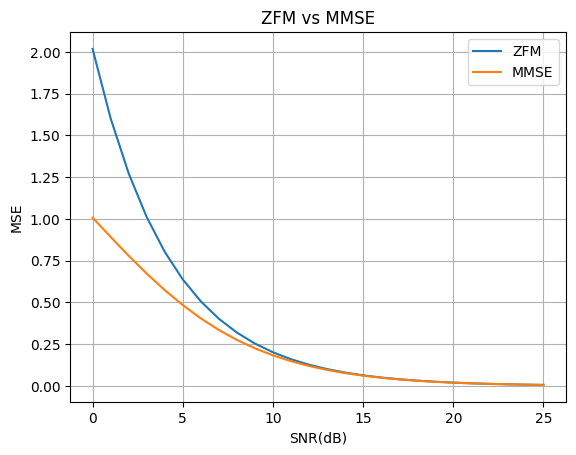

In [ ]:
plt.plot(snr_db,mse_zfm,label="ZFM")           #plot graoph for both
plt.plot(snr_db,mse_mmse,label="MMSE")

plt.xlabel("SNR(dB)")
plt.ylabel("MSE")
plt.title("ZFM vs MMSE")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("SNR|ZFM MSE|MMSE MSE|DIFF (%)")  #comapring the zfm and mmse improv in result

for snr,zfm,mmse in zip(snr_db,  mse_zfm,  mse_mmse):
    diff =(zfm-mmse)/zfm*100
    print(f"{snr:2d} |{zfm:.6f}|{mmse:.6f}|{diff:.2f}%")

SNR|ZFM MSE|MMSE MSE|DIFF (%)
 0 |2.017357|1.007679|50.05%
 1 |1.602444|0.892144|44.33%
 2 |1.272866|0.779627|38.75%
 3 |1.011073|0.672815|33.46%
 4 |0.803124|0.573849|28.55%
 5 |0.637944|0.484196|24.10%
 6 |0.506737|0.404620|20.15%
 7 |0.402516|0.335261|16.71%
 8 |0.319730|0.275756|13.75%
 9 |0.253970|0.225396|11.25%
10 |0.201736|0.183264|9.16%
11 |0.160244|0.148354|7.42%
12 |0.127287|0.119660|5.99%
13 |0.101107|0.096229|4.83%
14 |0.080312|0.077199|3.88%
15 |0.063794|0.061811|3.11%
16 |0.050674|0.049412|2.49%
17 |0.040252|0.039450|1.99%
18 |0.031973|0.031464|1.59%
19 |0.025397|0.025074|1.27%
20 |0.020174|0.019969|1.02%
21 |0.016024|0.015894|0.81%
22 |0.012729|0.012646|0.65%
23 |0.010111|0.010058|0.52%
24 |0.008031|0.007998|0.41%
25 |0.006379|0.006358|0.33%
